<a href="https://colab.research.google.com/github/ContiPaolo/EKF-SINDy/blob/main/notebooks/ShearBuilding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Shear building model
We consider a shear building under seismic excitations. The dynamical response of a 2 storey building can be described by the following equations:

$$
\begin{align}
m\ddot{x}_1(t)+c_1 \dot{x}_1 + k(2x_1(t)-x_2(t)) = -mb(t),\\
m\ddot{x}_2(t)+c_2 \dot{x}_2 + k(x_2(t)-x_1(t)) = -mb(t),\\
\end{align}
$$

where $m=625$ ton is the mass of each floor; $k$ is the inter-storey stiffness; $b(t)$ is the ground acceleration signal; $c_1$ and $c_2$ are coefficients set to have $1\%$ damping over the two eigenmodes of the building model.

We suppose we are able to measure displacements, velocities and accelerations of the two floors, and we aim to:

1. **Identify the equations of motion from the data (SINDy)**
2. **Estimate the states and the inter-storey stiffness $k$ (EKF-SINDy)**

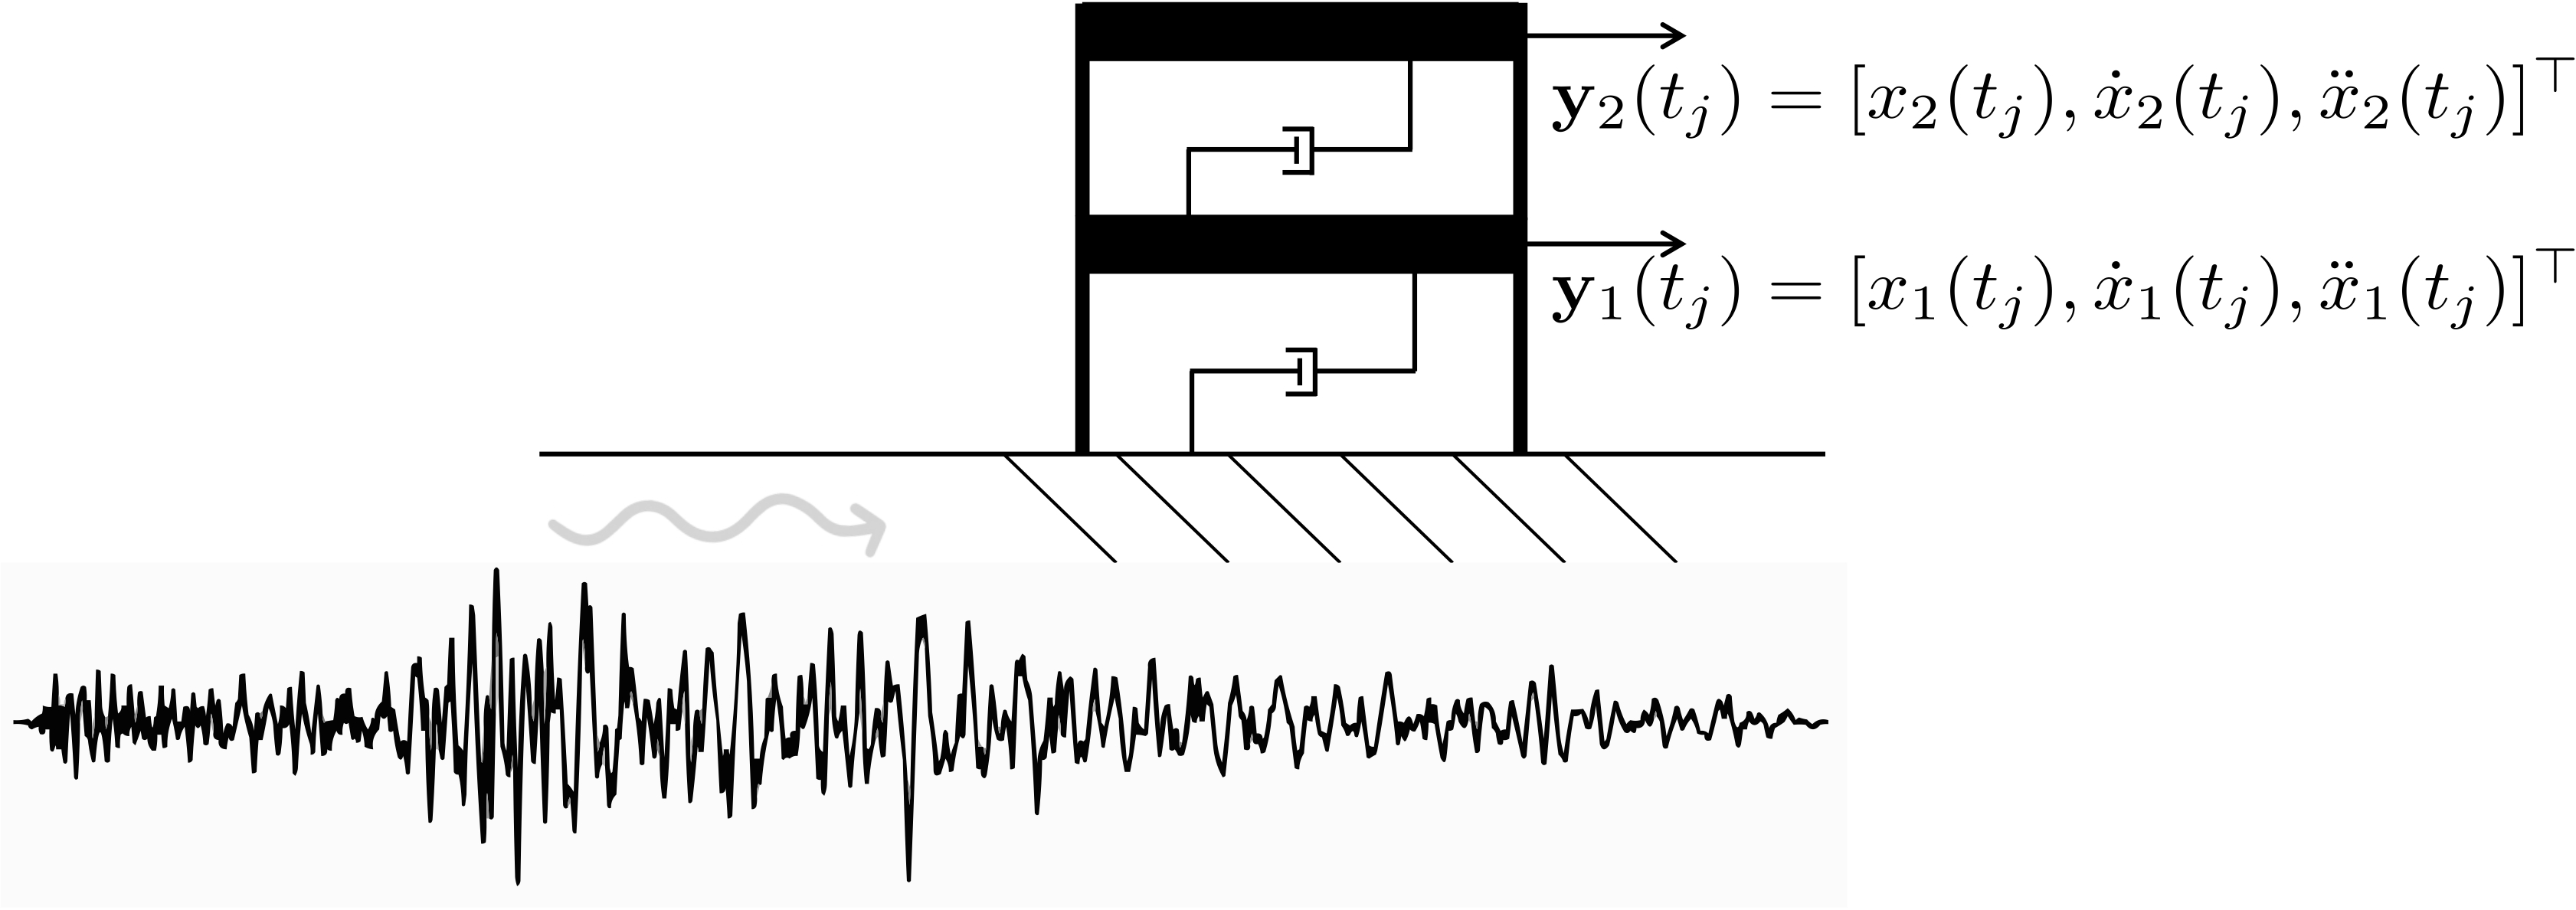

In [1]:
from IPython.display import Image, display

display(Image(filename="./shear_model.jpg"))

### Download data
Download the data at https://zenodo.org/records/11581079 and put the csv files in the `data/` folder
of the repository (or point the `EKFSINDY_DATA` environment variable to their folder).

In [ ]:
###########################  INSTALL EKF-SINDY (Colab only)  ###########################
# Colab: run this cell first. After installing, the runtime restarts automatically (to load the
# pinned numpy/scipy versions); then run the whole notebook, this cell will be skipped.
# Locally: run `uv sync --all-extras` in the repository and select the `.venv` kernel.
import sys

if "google.colab" in sys.modules:
    try:
        import ekfsindy  # noqa: F401
    except ImportError:
        %pip install "ekfsindy[notebooks] @ git+https://github.com/ContiPaolo/EKF-SINDy"
        import os

        os.kill(os.getpid(), 9)

In [2]:
%matplotlib inline

import warnings

warnings.filterwarnings("ignore", message="pkg_resources is deprecated")  # raised by pysindy 1.7.5

###########################                LIBRARIES                ###########################
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
import pysindy as ps

from ekfsindy import AugmentedEKF, SparseModel, SymbolicLibrary, observation
from ekfsindy.data import add_noise_with_snr, data_dir, read_dof_csv
from ekfsindy.plotting import plot_estimate

seed = 1
print("Data folder:", data_dir())

Data folder: /Users/contip/Desktop/ekfsindy/EKF-SINDy/data


In [3]:
###########################                SETUP                ###########################
# Displacements, velocities and accelerations of the two floors are all measured
N_ou = N_ov = N_oa = 2
N_f = 2      # number of forcing terms
N_param = 1  # number of parameters (inter-storey stiffness)

snr_noise_displ = snr_noise_veloc = snr_noise_accel = 15

In [4]:
########################       LOAD TRAIN DATA      ###########################
T_train = 1000  # training series length

U_train = read_dof_csv("_U_concat_", "train", T_train, N_ou)
V_train = read_dof_csv("_V_concat_", "train", T_train, N_ov)
A_train = read_dof_csv("_A_concat_", "train", T_train, N_oa)
param_train = read_dof_csv("theta_", "train", T_train, N_param)
F_train = read_dof_csv("F_", "train", T_train, N_f)

In [5]:
########################       LOAD TEST DATA      ###########################
T = 40960  # testing series length
np.random.seed(seed)

U_test_noisefree = read_dof_csv("_U_concat_", "test", T, N_ou)
V_test_noisefree = read_dof_csv("_V_concat_", "test", T, N_ov)
A_test_noisefree = read_dof_csv("_A_concat_", "test", T, N_oa)
U_test = add_noise_with_snr(U_test_noisefree, snr_noise_displ)
V_test = add_noise_with_snr(V_test_noisefree, snr_noise_veloc)
A_test = add_noise_with_snr(A_test_noisefree, snr_noise_accel)
param_test = read_dof_csv("theta_", "test", T, N_param)
F_test = read_dof_csv("F_", "test", T, N_f)

In [6]:
########################       SCALE DATA      ###########################
scale_V = np.max(np.abs(V_train))
scale_F = np.max(np.abs(F_train))
scale_param = np.max(np.abs(param_train))
# Displacements are further scaled by their maximum
scale_x = np.max(np.abs(U_train / scale_V))
scale_U = scale_V * scale_x


def scaled_inputs(U, V, A):
    """Scaled states [x1, x2, v1, v2] and accelerations."""
    return np.concatenate([U / scale_V / scale_x, V / scale_V], axis=-1), A / scale_V

In [7]:
######################      SYMBOLIC SINDy LIBRARY       ######################
# Library variables: displacements, velocities, stiffness and forcing
variables = ["x1", "x2", "v1", "v2", "w0", "F1", "F2"]
# Linear terms in all variables + quadratic terms in the states and the stiffness
linear_terms = SymbolicLibrary(variables, variables)
quadratic_terms = SymbolicLibrary.polynomial(variables[:5], degree=2, include_bias=False)
library = linear_terms + SymbolicLibrary(variables, quadratic_terms.expressions[5:])
print(library)

######################      PREPARE DATA for SINDy       ######################
dt = 0.001
X, X_dot, inputs = [], [], []
for i in range(len(U_train)):
    x_i, a_i = scaled_inputs(U_train[i], V_train[i], A_train[i])
    X.append(x_i)
    X_dot.append(np.concatenate([V_train[i] / scale_V / scale_x, a_i], axis=1))
    inputs.append(np.concatenate([param_train[i] / scale_param, F_train[i] / scale_F], axis=1))

SymbolicLibrary(variables=['x1', 'x2', 'v1', 'v2', 'w0', 'F1', 'F2'], features=['x1', 'x2', 'v1', 'v2', 'w0', 'F1', 'F2', 'x1**2', 'x1*x2', 'v1*x1', 'v2*x1', 'w0*x1', 'x2**2', 'v1*x2', 'v2*x2', 'w0*x2', 'v1**2', 'v1*v2', 'v1*w0', 'v2**2', 'v2*w0', 'w0**2'])


In [8]:
######################      CREATE SINDy model       ######################
# The symbolic library is handed to pysindy as an equivalent CustomLibrary
sindy = ps.SINDy(feature_library=library.to_pysindy(), optimizer=ps.STLSQ(threshold=1e-2))
sindy.fit(X, t=dt, u=inputs, multiple_trajectories=True, x_dot=X_dot)

model = SparseModel.from_pysindy(sindy, library, n_params=N_param, n_inputs=N_f)
model.print()

(x1)' = 17.615*v1
(x2)' = 17.615*v2
(v1)' = -1218346662.022*F1 + 1218346657.772*F2 - 0.534*v1**2 + 0.598*v1*v2 - 3.768*v1*w0 + 2.984*v1*x1 - 1.844*v1*x2 - 2.25*v1 - 0.164*v2**2 + 1.776*v2*w0 - 1.883*v2*x1 + 1.164*v2*x2 + 1.112*v2 - 351.04*w0*x1 + 174.107*w0*x2 - 0.088*x1**2 + 0.055*x1*x2 - 0.716*x1 + 0.446*x2
(v2)' = -1218939577.404*F1 + 1218939573.153*F2 - 0.09*v1**2 + 0.036*v1*v2 + 3.186*v1*w0 - 0.01*v1*x1 + 0.056*v1*x2 + 0.922*v1 + 0.014*v2**2 - 2.861*v2*w0 - 0.03*v2*x2 - 1.023*v2 + 193.088*w0*x1 - 188.664*w0*x2 - 3.33*x1**2 + 4.031*x1*x2 - 0.557*x1 - 1.218*x2**2 + 0.346*x2


In [9]:
######################      STATE-TO-OBSERVATION MAP (h)       ######################
# Displacements and velocities are states; accelerations are the identified dv/dt
h = observation.states_and_rates(model, state_indices=[0, 1, 2, 3], rate_indices=[2, 3])

## Kalman Filter

In [10]:
######################      KALMAN FILTER       ######################
# Kalman filter part - select the test case
param_rel_error = -0.2
idx_test = 9

states, acc = scaled_inputs(U_test[idx_test], V_test[idx_test], A_test[idx_test])
states_nf, acc_nf = scaled_inputs(U_test_noisefree[idx_test], V_test_noisefree[idx_test],
                                  A_test_noisefree[idx_test])
y = np.concatenate([states, acc], axis=1)  # measurements [x1, x2, v1, v2, a1, a2]
forcing = F_test[idx_test] / scale_F
true_param = param_test[idx_test, :, 0] / scale_param

In [11]:
# Kalman filter initialisation
# Initial uncertainty of states and stiffness
p0_ou, p0_ov, p0_param = 1e-5, 1e-5, 2e-5
# Process noise
q_ou, q_ov, q_param = 1e-4, 1e-4, 1e-8
# Measurement noise
r_ou, r_ov, r_oa = 5e-1, 5e-3, 5e0

P0 = np.diag([p0_ou] * N_ou + [p0_ov] * N_ov + [p0_param])
Q = np.diag([q_ou] * N_ou + [q_ov] * N_ov + [q_param])
R = np.diag([r_ou] * N_ou + [r_ov] * N_ov + [r_oa] * N_oa)

ekf = AugmentedEKF(model, h, Q=Q, R=R, dt=dt)
z0 = model.augmented_state(y[0, :N_ou + N_ov], true_param[0] * (1 - param_rel_error))

In [12]:
#%% Kalman filter run
result = ekf.run(z0, P0, y, u=forcing)

In [13]:
#%% Rescale to physical units for the plots
t_axis = np.arange(T) * dt
scales = np.array([scale_U] * N_ou + [scale_V] * N_ov + [scale_param])
result_phys = dataclasses.replace(result, mean=result.mean * scales,
                                  cov=result.cov * np.outer(scales, scales))
measured = np.concatenate([states * scales[:4], acc * scale_V], axis=1)
noisefree = np.concatenate([states_nf * scales[:4], acc_nf * scale_V], axis=1)

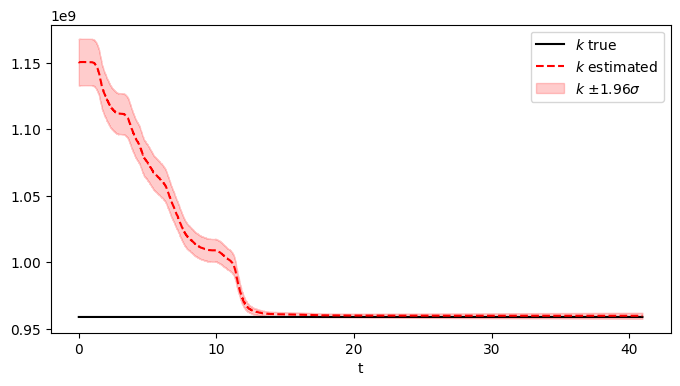

In [14]:
#%% Parameter
plt.figure(figsize=[8, 4])
plot_estimate(t_axis, result_phys, 4, truth=param_test[idx_test, :, 0], label="$k$")
plt.show()

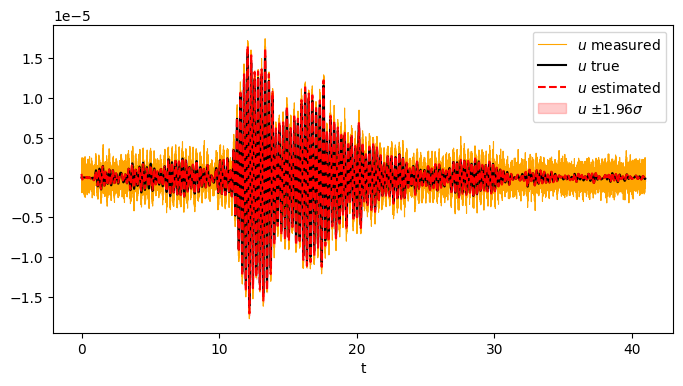

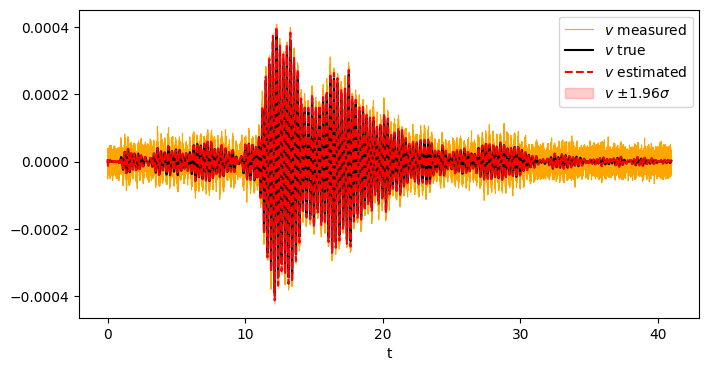

In [15]:
#%% displacement and velocity of the first floor
for index, label in [(0, "$u$"), (2, "$v$")]:
    plt.figure(figsize=[8, 4])
    plot_estimate(t_axis, result_phys, index, truth=noisefree[:, index], measured=measured[:, index],
                  label=label)
    plt.show()

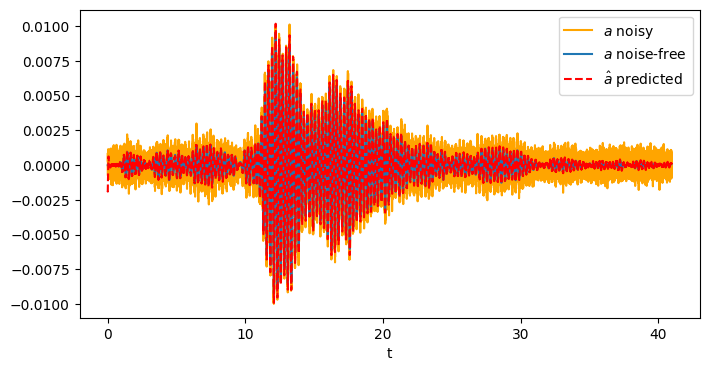

In [16]:
#%% acceleration of the first floor
plt.figure(figsize=[8, 4])
plt.plot(t_axis, measured[:, 4], "orange", label="$a$ noisy")
plt.plot(t_axis, noisefree[:, 4], label="$a$ noise-free")
plt.plot(t_axis, result.obs[:, 4] * scale_V, "r--", label=r"$\hat{a}$ predicted")
plt.legend()
plt.xlabel("t")
plt.show()